# Ejercicio 7. Verificación de la mediana de dos arreglos ordenados

Este cuaderno acompaña al informe [`ejercicio-07.md`](ejercicio-07.md). Ejecuta
el mismo algoritmo, comprueba el invariante y el potencial, verifica las
posiciones de salida de la cota de información y genera `ejercicio-07.png`.
Las secciones siguen la numeración del informe.

La respuesta es el $n$-ésimo menor entre los $2n$ elementos, contando repetidos.
No se promedian las posiciones centrales. Se cuenta una comparación de tres
resultados por llamada al comparador. La construcción de casos, las aserciones
y la ordenación de referencia quedan fuera del costo del algoritmo.
Para reproducir el cuaderno hacen falta Python 3, `matplotlib` e `IPython`.


In [1]:
from functools import total_ordering
from itertools import combinations, combinations_with_replacement
from random import Random

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display


## 1. Formulación y modelo

Dos arreglos no decrecientes del mismo largo positivo $n$, con acceso aleatorio,
contienen claves de un orden total. Se devuelve una clave de entrada, sin modificar
los arreglos. El oráculo siguiente ordena una copia conjunta y toma la posición
$n-1$ de Python. Su costo no forma parte del algoritmo.


In [2]:
def reference_median(A, B):
    assert len(A) == len(B) > 0
    return sorted(list(A) + list(B))[len(A) - 1]


def is_sorted(A):
    return all(A[k] <= A[k + 1] for k in range(len(A) - 1))


def first_true_cut(A, B):
    # Oráculo lineal independiente para el índice buscado, solo en las pruebas.
    n = len(A)
    return next((i for i in range(n) if B[n - i - 1] <= A[i]), n)


assert reference_median([1], [2]) == 1
assert reference_median([1, 1], [1, 1]) == 1


## 2. Partición y algoritmo

El corte $i$ toma $i$ elementos de $A$ y $j=n-i$ de $B$ para formar los $n$
de la izquierda. Se busca el primer $i$ tal que $P(i)$ sea verdadero, donde
$P(i)$ es $B[n-i-1]\le A[i]$ si $i<n$, y $P(n)$ es verdadero.
La condición es monótona: al aumentar $i$, el lado de $A$ no disminuye y el de
$B$ no aumenta. El código es idéntico al del informe.


In [3]:
def compare(x, y):
    return (x > y) - (x < y)  # -1, 0 o 1


def lower_median(A, B, compare=compare):
    n = len(A)
    if n == 0 or len(B) != n:
        raise ValueError("se requieren dos arreglos del mismo largo positivo")
    lo, hi = 0, n
    while lo < hi:
        i = (lo + hi) // 2
        j = n - i
        if compare(A[i], B[j - 1]) < 0:
            lo = i + 1
        else:
            hi = i
    i, j = lo, n - lo
    if i == 0:
        return B[j - 1]
    if j == 0:
        return A[i - 1]
    if compare(A[i - 1], B[j - 1]) >= 0:
        return A[i - 1]
    return B[j - 1]


## 3. Invariante, correctitud y terminación

La versión vigilada comprueba $0\le lo\le hi\le n$, $P(hi)$ verdadero y todos
los índices anteriores a $lo$ falsos. También verifica que el primer corte
verdadero permanece en el intervalo y que $\Phi=hi-lo$ se reduce al menos a
la mitad. Al salir se comprueban ambas desigualdades cruzadas, el tamaño $n$
de la izquierda y que su máximo es menor o igual al mínimo de la derecha.

Las consultas del algoritmo del informe se registran con un comparador y se
contrastan con las de la versión vigilada, incluida la comparación final si existe.


In [4]:
class CountingCompare:
    def __init__(self):
        self.calls = []

    def __call__(self, x, y):
        result = compare(x, y)
        self.calls.append((x, y, result))
        return result


def watched_median(A, B):
    n = len(A)
    predicates = [B[n - k - 1] <= A[k] for k in range(n)] + [True]
    assert predicates == sorted(predicates)
    p = first_true_cut(A, B)
    assert p == predicates.index(True)
    lo, hi = 0, n
    trace, calls = [], []

    def invariant():
        assert 0 <= lo <= p <= hi <= n
        assert predicates[hi]
        assert not any(predicates[:lo])

    invariant()
    while lo < hi:
        old_lo, old_hi = lo, hi
        before = hi - lo
        i = (lo + hi) // 2
        j = n - i
        assert 0 <= i < n and 1 <= j <= n
        r = compare(A[i], B[j - 1])
        calls.append((A[i], B[j - 1], r))
        assert (r >= 0) is predicates[i]
        if r < 0:
            lo = i + 1
        else:
            hi = i
        after = hi - lo
        assert 0 <= after <= before // 2 < before
        trace.append(dict(lo=old_lo, hi=old_hi, i=i, j=j, a=A[i],
                          b=B[j - 1], result=r, before=before, after=after,
                          next_lo=lo, next_hi=hi))
        invariant()
    assert lo == hi == p
    i, j = p, n - p
    if i > 0 and j < n:
        assert A[i - 1] < B[j]
    if j > 0 and i < n:
        assert B[j - 1] <= A[i]
    left = list(A[:i]) + list(B[:j])
    right = list(A[i:]) + list(B[j:])
    assert len(left) == len(right) == n
    assert max(left) <= min(right)
    if i == 0:
        answer = B[j - 1]
    elif j == 0:
        answer = A[i - 1]
    else:
        r = compare(A[i - 1], B[j - 1])
        calls.append((A[i - 1], B[j - 1], r))
        answer = A[i - 1] if r >= 0 else B[j - 1]
    assert answer == max(left) == reference_median(A, B)
    return answer, trace, calls, p


def verify_case(A, B):
    assert len(A) == len(B) > 0 and is_sorted(A) and is_sorted(B)
    snapshot = (tuple(map(id, A)), tuple(map(id, B)))
    counter = CountingCompare()
    actual = lower_median(A, B, compare=counter)
    expected = reference_median(A, B)
    watched, trace, calls, p = watched_median(A, B)
    assert actual == watched == expected
    assert counter.calls == calls
    assert len(trace) <= len(A).bit_length()
    assert len(calls) == len(trace) + int(0 < p < len(A))
    assert len(calls) <= len(A).bit_length() + 1
    if len(A) == 1:
        assert len(calls) == 1
    assert (tuple(map(id, A)), tuple(map(id, B))) == snapshot
    return actual, trace, p, len(calls)


example_A = [1, 2, 3, 10, 11]
example_B = [4, 5, 6, 7, 8]
answer, example_trace, cut, count = verify_case(example_A, example_B)
assert (answer, cut, count) == (5, 3, 4)
example_rows = [(r['lo'], r['hi'], r['i'], r['j'], r['a'], r['b'],
                 r['next_lo'], r['next_hi'], r['after']) for r in example_trace]
assert example_rows == [
    (0, 5, 2, 3, 3, 6, 3, 5, 2),
    (3, 5, 4, 1, 11, 4, 3, 4, 1),
    (3, 4, 3, 2, 10, 5, 3, 3, 0),
]
print('Tabla 1. Búsqueda del corte del ejemplo')
print('lo hi  i j  A[i] B[j-1]  nuevo lo hi  potencial')
for lo, hi, i, j, a, b, next_lo, next_hi, phi in example_rows:
    print(f'{lo:2} {hi:2} {i:2} {j:1} {a:5} {b:6} {next_lo:9} {next_hi:2} {phi:10}')
print('Corte: i=3, j=2; izquierda A=[1,2,3], B=[4,5]')
print('Máximo izquierdo: 5; comparaciones totales: 4')


Tabla 1. Búsqueda del corte del ejemplo
lo hi  i j  A[i] B[j-1]  nuevo lo hi  potencial
 0  5  2 3     3      6         3  5          2
 3  5  4 1    11      4         3  4          1
 3  4  3 2    10      5         3  3          0
Corte: i=3, j=2; izquierda A=[1,2,3], B=[4,5]
Máximo izquierdo: 5; comparaciones totales: 4


## 4. Costo y cota de información

La búsqueda usa como máximo $\lceil\log_2(n+1)\rceil$ comparaciones; elegir el
máximo izquierdo usa una más si el corte es interior. El costo es
$O(\log(n+1))$ y la memoria auxiliar es $\Theta(1)$. La implementación usa
`n.bit_length()` solo en las pruebas para representar exactamente
$\lceil\log_2(n+1)\rceil$, sin redondeos de punto flotante.

La cota de información es $\lceil\log_2(2n)\rceil$: cualquiera de las $2n$
posiciones puede ser la mediana y necesita una hoja propia. Con claves distintas,
solo hay dos resultados relevantes por comparación. Se cuentan posiciones de
salida, no rangos numéricos. La construcción siguiente usa claves etiquetadas
y comprueba cada posición como respuesta, para largos 1 a 64.


In [5]:
@total_ordering
class Key:
    __slots__ = ('rank', 'label')

    def __init__(self, rank, label):
        self.rank = rank
        self.label = label

    def __lt__(self, other):
        return self.rank < other.rank

    def __eq__(self, other):
        return isinstance(other, Key) and self.rank == other.rank

    def __repr__(self):
        return f'{self.label}:{self.rank}'


def make_output_case(n, source, k):
    # k se numera desde 1. Los primeros n elementos terminan en source[k-1].
    assert n >= 1 and source in ('A', 'B') and 1 <= k <= n
    other = 'B' if source == 'A' else 'A'
    order = ([(other, i) for i in range(n - k)]
             + [(source, i) for i in range(k)]
             + [(source, i) for i in range(k, n)]
             + [(other, i) for i in range(n - k, n)])
    positions = {label: Key(rank, label) for rank, label in enumerate(order)}
    A = [positions['A', i] for i in range(n)]
    B = [positions['B', i] for i in range(n)]
    return A, B


output_cases = 0
for n in range(1, 65):
    labels = set()
    for source in ('A', 'B'):
        for k in range(1, n + 1):
            A, B = make_output_case(n, source, k)
            result, _, _, _ = verify_case(A, B)
            expected = A[k - 1] if source == 'A' else B[k - 1]
            assert result is expected
            assert result.label == (source, k - 1)
            assert result.rank == n - 1
            labels.add(result.label)
            output_cases += 1
    assert len(labels) == 2 * n

assert output_cases == 4160
print(f'ok: {output_cases} instancias etiquetadas; cada una de las 2n posiciones puede ser la mediana')
print('Los rangos de las medianas coinciden; sus posiciones de entrada son distintas.')


ok: 4160 instancias etiquetadas; cada una de las 2n posiciones puede ser la mediana
Los rangos de las medianas coinciden; sus posiciones de entrada son distintas.


In [6]:
def make_partition_case(n, p):
    # Orden conjunto: B[:n-p], A[:p], A[p:], B[n-p:].
    # Asignar rangos en ese orden hace que el primer corte verdadero sea p.
    assert 0 <= p <= n
    j = n - p
    A = list(range(j, n)) + list(range(n, 2 * n - p))
    B = list(range(j)) + list(range(2 * n - p, 2 * n))
    return A, B


worst_records = []
partition_cases = 0
for n in range(1, 129):
    worst = 0
    for p in range(n + 1):
        A, B = make_partition_case(n, p)
        result, _, actual_cut, count = verify_case(A, B)
        assert result == n - 1 and actual_cut == p
        worst = max(worst, count)
        partition_cases += 1
    upper = n.bit_length() + 1
    information = (2 * n - 1).bit_length()
    assert information <= worst <= upper
    assert upper - information in (0, 1)
    worst_records.append(dict(n=n, worst=worst, upper=upper, information=information))

assert partition_cases == 8384
table_sizes = [1, 2, 3, 4, 8, 16, 32, 64, 128]
table = [(n, worst_records[n - 1]['worst'], worst_records[n - 1]['upper'],
          worst_records[n - 1]['information']) for n in table_sizes]
assert table == [
    (1, 1, 2, 1), (2, 3, 3, 2), (3, 3, 3, 3), (4, 4, 4, 3),
    (8, 5, 5, 4), (16, 6, 6, 5), (32, 7, 7, 6),
    (64, 8, 8, 7), (128, 9, 9, 8),
]
print('Tabla 2. Peor caso medido, cota superior e información')
print('  n  peor medido  cota superior  información')
for n, worst, upper, information in table:
    print(f'{n:3} {worst:12} {upper:14} {information:12}')
print(f'ok: {partition_cases} cortes; todos los posibles para cada largo de 1 a 128')


Tabla 2. Peor caso medido, cota superior e información
  n  peor medido  cota superior  información
  1            1              2            1
  2            3              3            2
  3            3              3            3
  4            4              4            3
  8            5              5            4
 16            6              6            5
 32            7              7            6
 64            8              8            7
128            9              9            8
ok: 8384 cortes; todos los posibles para cada largo de 1 a 128


## 5. Verificación numérica

Se enumeran todos los pares de arreglos no decrecientes de largos 1 a 8 con
valores en $\{0,1,2\}$. Después se enumeran todas las intercalaciones de dos
arreglos de largos 1 a 8 con claves distintas: se eligen los rangos que recibe
$A$ y se asignan los restantes a $B$. Esto cubre todos los órdenes conjuntos
posibles, conservando el orden interno de cada arreglo.

Cada caso comprueba el resultado contra la ordenación conjunta, los índices,
el invariante, la partición, el potencial, el conteo y la conservación de las
entradas. Se añaden 900 pares con semilla fija y pruebas de largos inválidos.


In [7]:
repeated_cases = 0
for n in range(1, 9):
    arrays = list(combinations_with_replacement(range(3), n))
    for A in arrays:
        for B in arrays:
            verify_case(A, B)
            repeated_cases += 1
assert repeated_cases == 4916
print(f'ok: {repeated_cases} pares exhaustivos con repetidos, para largos 1 a 8')

interleaving_cases = 0
for n in range(1, 9):
    labels = set()
    for a_ranks in combinations(range(2 * n), n):
        selected = set(a_ranks)
        A = list(a_ranks)
        B = [rank for rank in range(2 * n) if rank not in selected]
        result, _, _, _ = verify_case(A, B)
        assert result == n - 1
        label = ('A', A.index(result)) if result in selected else ('B', B.index(result))
        labels.add(label)
        interleaving_cases += 1
    assert len(labels) == 2 * n
assert interleaving_cases == 17576
print(f'ok: {interleaving_cases} intercalaciones exhaustivas con claves distintas')

rng = Random(2026)
random_cases = 0
for n in [1, 2, 3, 4, 8, 16, 32, 64, 128]:
    for _ in range(100):
        A = sorted(rng.choices(range(-2 * n, 2 * n + 1), k=n))
        B = sorted(rng.choices(range(-2 * n, 2 * n + 1), k=n))
        verify_case(A, B)
        random_cases += 1
assert random_cases == 900
print(f'ok: {random_cases} pares adicionales reproducibles con semilla 2026')

invalid_cases = [([], []), ([], [1]), ([1], []), ([1], [1, 2]), ([1, 2], [1])]
for A, B in invalid_cases:
    try:
        lower_median(A, B)
    except ValueError:
        pass
    else:
        raise AssertionError('debió rechazarse un largo inválido')
print(f'ok: {len(invalid_cases)} casos de largos inválidos producen ValueError')


ok: 4916 pares exhaustivos con repetidos, para largos 1 a 8
ok: 17576 intercalaciones exhaustivas con claves distintas
ok: 900 pares adicionales reproducibles con semilla 2026
ok: 5 casos de largos inválidos producen ValueError


## Figura 1

A la izquierda se muestra el corte del ejemplo, con tres claves de $A$ y dos
de $B$ en la mitad izquierda. Su máximo, 5, es la mediana inferior. A la derecha
se comparan el peor caso medido sobre todos los cortes, la cota superior y
la cota de información. El eje horizontal usa escala logarítmica de base 2.


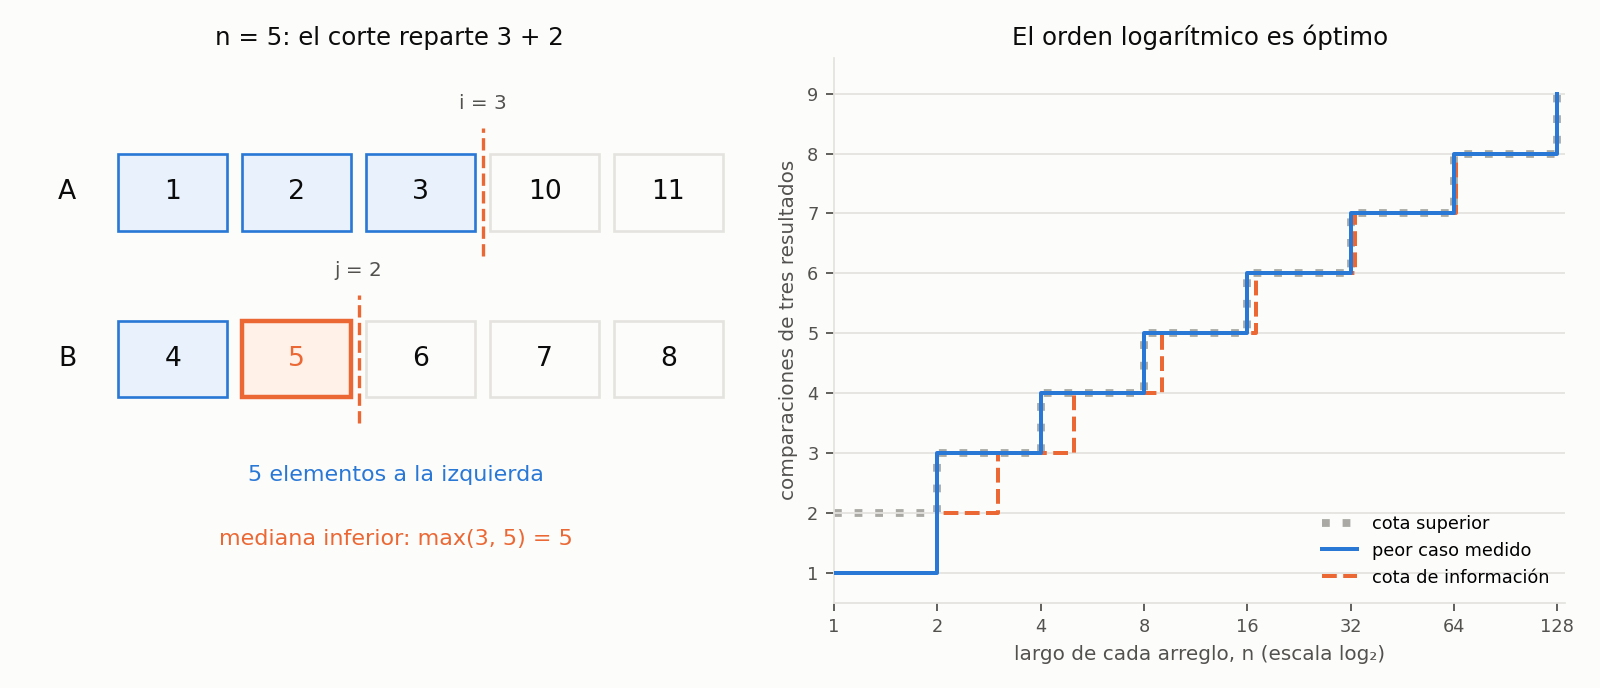

In [8]:
blue, orange = '#2a78d6', '#eb6834'
ink, secondary_ink = '#0b0b0b', '#52514e'
grid_color, background = '#e4e3df', '#fcfcfb'
fig, (ax_cut, ax_cost) = plt.subplots(1, 2, figsize=(10, 4.3), dpi=160)
fig.patch.set_facecolor(background)

for label, array, y, cut_index in [('A', example_A, 1.3, 3), ('B', example_B, 0, 2)]:
    ax_cut.text(-0.85, y, label, ha='center', va='center', color=ink, fontsize=12)
    for k, value in enumerate(array):
        is_answer = label == 'B' and k == 1
        fill = '#fff0e8' if is_answer else '#e8f1fc' if k < cut_index else background
        edge = orange if is_answer else blue if k < cut_index else grid_color
        ax_cut.add_patch(Rectangle((k - 0.44, y - 0.3), 0.88, 0.6,
                                   facecolor=fill, edgecolor=edge,
                                   lw=2 if is_answer else 1.2))
        ax_cut.text(k, y, str(value), ha='center', va='center',
                     fontsize=12, color=orange if is_answer else ink)
    x_cut = cut_index - 0.5
    ax_cut.plot([x_cut, x_cut], [y - 0.5, y + 0.5], color=orange, lw=1.5, ls='--')
    cut_label = f'i = {cut_index}' if label == 'A' else f'j = {cut_index}'
    ax_cut.text(x_cut, y + 0.65, cut_label, ha='center', color=secondary_ink, fontsize=9)
ax_cut.text(1.8, -0.95, '5 elementos a la izquierda', ha='center', color=blue, fontsize=10)
ax_cut.text(1.8, -1.45, 'mediana inferior: max(3, 5) = 5', ha='center', color=orange, fontsize=10)
ax_cut.set_title('n = 5: el corte reparte 3 + 2', color=ink, fontsize=11)
ax_cut.set_xlim(-1.2, 4.7)
ax_cut.set_ylim(-1.9, 2.35)
ax_cut.axis('off')

ns = [r['n'] for r in worst_records]
worsts = [r['worst'] for r in worst_records]
uppers = [r['upper'] for r in worst_records]
information = [r['information'] for r in worst_records]
ax_cost.step(ns, uppers, where='post', color='#aaa9a4', lw=3.5, ls=':',
              label='cota superior', zorder=1)
ax_cost.step(ns, worsts, where='post', color=blue, lw=1.8,
              label='peor caso medido', zorder=3)
ax_cost.step(ns, information, where='post', color=orange, lw=1.8, ls='--',
              label='cota de información', zorder=2)
ax_cost.set_xscale('log', base=2)
ax_cost.set_xlim(1, 135)
ax_cost.set_ylim(0.5, 9.6)
ax_cost.set_xticks([1, 2, 4, 8, 16, 32, 64, 128], labels=['1', '2', '4', '8', '16', '32', '64', '128'])
ax_cost.set_yticks(range(1, 10))
ax_cost.set_title('El orden logarítmico es óptimo', color=ink, fontsize=11)
ax_cost.set_xlabel('largo de cada arreglo, n (escala log₂)', color=secondary_ink, fontsize=9)
ax_cost.set_ylabel('comparaciones de tres resultados', color=secondary_ink, fontsize=9)
ax_cost.set_facecolor(background)
ax_cost.grid(axis='y', color=grid_color, lw=0.8)
for side in ['top', 'right']:
    ax_cost.spines[side].set_visible(False)
for side in ['left', 'bottom']:
    ax_cost.spines[side].set_color(grid_color)
ax_cost.tick_params(colors=secondary_ink, labelsize=8)
ax_cost.legend(frameon=False, fontsize=8, loc='lower right')
fig.tight_layout()
fig.savefig('ejercicio-07.png', facecolor=background)
plt.close(fig)
display(Image(filename='ejercicio-07.png'))


## 6. Conclusiones

La monotonía permite buscar por bisección el número de elementos que aporta
$A$ a los $n$ menores. El primer corte verdadero cumple ambas desigualdades
cruzadas y su máximo izquierdo es la mediana inferior. La distancia entre los
extremos del intervalo demuestra terminación y costo logarítmico. Las $2n$
posiciones posibles de salida dan una cota de información del mismo orden.
El algoritmo admite repetidos y usa memoria auxiliar constante.

Las pruebas cubren las familias enumeradas; las demostraciones del informe
establecen el resultado para cualquier largo positivo.


In [9]:
print('Todas las comprobaciones finalizaron correctamente.')
print(f'Pares exhaustivos con repetidos: {repeated_cases}')
print(f'Intercalaciones con claves distintas: {interleaving_cases}')
print(f'Pares adicionales reproducibles: {random_cases}')
print(f'Cortes enumerados: {partition_cases}')
print(f'Instancias con salidas etiquetadas: {output_cases}')
print('Figura guardada en ejercicio-07.png')


Todas las comprobaciones finalizaron correctamente.
Pares exhaustivos con repetidos: 4916
Intercalaciones con claves distintas: 17576
Pares adicionales reproducibles: 900
Cortes enumerados: 8384
Instancias con salidas etiquetadas: 4160
Figura guardada en ejercicio-07.png
